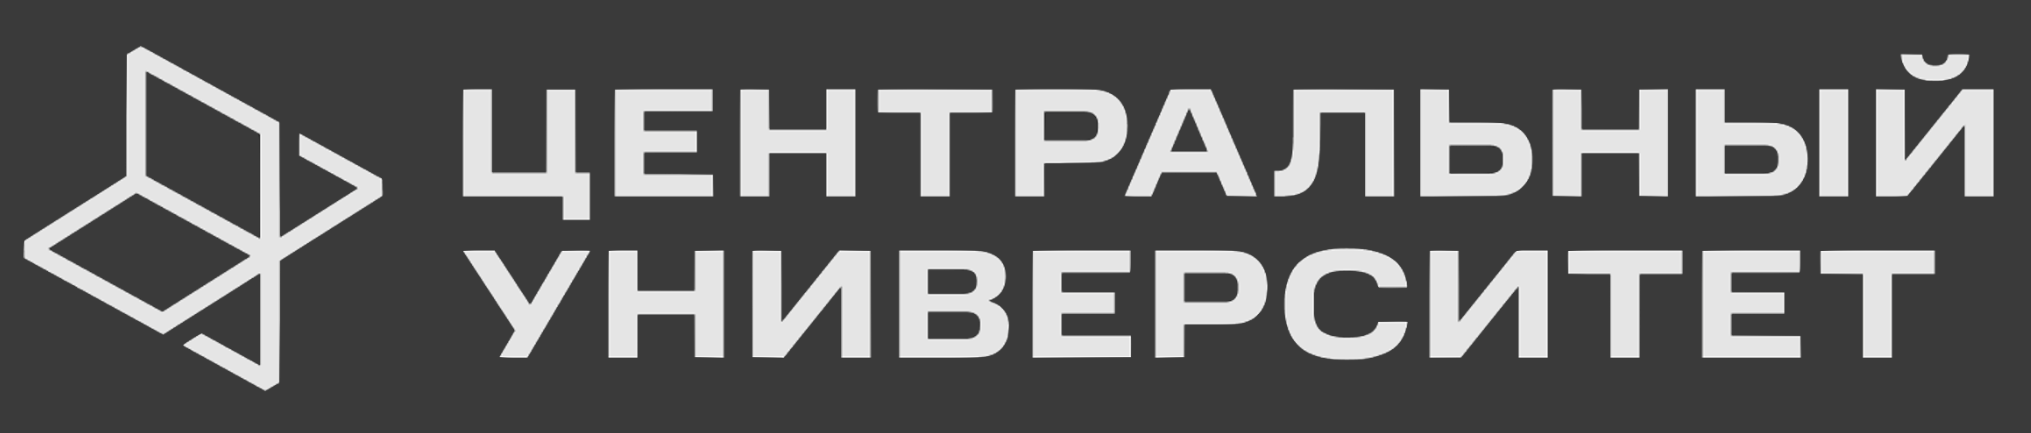

<hr style="border:2px solid gray">

## Домашнее задание 2. Задача детектирования и классификации объектов


# О формате сдачи

🔷 **<font color='plum'>При решении ноутбука используй данный шаблон.</font>**

    ✅ Можно добавлять новые ячейки любых типов.
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий.


🔷 **<font color='plum'>При оценивании задач учитывается код.</font>**

    ✅ Задания, в которых необходим код, обычно помечаются фразами «Your code here» / «Твой код» и аналогичными.
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов.
    ❌ Наличие работоспособного кода в ноутбуке, если на сказано иного, обязательно.

🔷 **<font color='plum'>При оценивании задач учитываются выводы.</font>**

    ✅ Задания, в которых необходимы выводы, обычно помечаются фразами «Вывод» / «Ответ на вопрос» / «Твой текст» и аналогичными.
    ✅ Обычно выводы подразумевают под собой текстовый ответ (можно писать Markdown, LaTeX).
    ✅ Сопутствующие изображения, графики, таблички приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл.

----
## <font color='OrangeRed'>**Внимание! Аларм! Ахтунг!**</font>

* Данный ноутбук желательно выполнять на внутренней платформе <font color='DarkSeaGreen'>**jupyter.culab**</font> ЦУ.

* Работоспособность данного ноутбука проверена именно на <font color='DarkSeaGreen'>**jupyter.culab**</font>, работоспособность «из-под коробки» на других платформах мы не гарантируем.

* Ты можешь делать задание у себя локально / Google Colab / Kaggle и пр. при желании, однако работать с дополнительными файлами и настраивать окружение придётся самостоятельно.

* Подробнее об использовании внутренней платформы читай в описании курса.

Скачиваем требуемые программные коды.

In [1]:
"""
!mkdir -p utils
!curl -O https://files.culab.ru/files/public/DeepLearningAdvanced/utils/multibox_loss.py  --output-dir utils
!curl -O https://files.culab.ru/files/public/DeepLearningAdvanced/utils/prior_boxes.py    --output-dir utils
!curl -O https://files.culab.ru/files/public/DeepLearningAdvanced/utils/voc_dataloader.py --output-dir utils
!curl -O https://files.culab.ru/files/public/DeepLearningAdvanced/utils/voc_dataset.py    --output-dir utils
!curl -O https://files.culab.ru/files/public/DeepLearningAdvanced/utils/voc_metrics.py    --output-dir utils
"""

'\n!mkdir -p utils\n!curl -O https://files.culab.ru/files/public/DeepLearningAdvanced/utils/multibox_loss.py  --output-dir utils\n!curl -O https://files.culab.ru/files/public/DeepLearningAdvanced/utils/prior_boxes.py    --output-dir utils\n!curl -O https://files.culab.ru/files/public/DeepLearningAdvanced/utils/voc_dataloader.py --output-dir utils\n!curl -O https://files.culab.ru/files/public/DeepLearningAdvanced/utils/voc_dataset.py    --output-dir utils\n!curl -O https://files.culab.ru/files/public/DeepLearningAdvanced/utils/voc_metrics.py    --output-dir utils\n'

Скачиваем требуемый набор данных в разрешении $640{\times}360$.

In [2]:
#!curl -O https://files.culab.ru/files/public/DeepLearningAdvanced/dataset_gs198-05_640x360.tar.gz

Скачиваем требуемый набор данных в разрешении $1280{\times}720$.

In [3]:
#!curl -O https://files.culab.ru/files/public/DeepLearningAdvanced/dataset_gs198-05_1280x720.tar.gz

Ставим дополнительные библиотеки.

In [4]:
!pip install albumentations torchview torchmetrics pycocotools

Looking in indexes: https://artifactory.tcsbank.ru/artifactory/api/pypi/python-all/simple

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip


---
## Формулировка задания

- <font color='DarkOrange'> **[3 баллa]** </font> Воспользоваться материалами семинара, разработать модель на основе архитектуры `ResNet18`.
- <font color='DarkOrange'> **[3 балла]** </font>Натренировать модель на основе архитектуры `ResNet18`.
- <font color='DarkOrange'> **[1 балл]** </font>Сравнить скорость работы моделей, основаных на `VGG16` и `ResNet18`.
- <font color='DarkOrange'> **[1 балл]** </font>Сравнить между собой метрики `MAP` для натренированных моделей, основаных на `VGG16` и `ResNet18`.
- <font color='DarkOrange'> **[2 балла]** </font>Визуализация результатов и описание проведённых экспериментов, выводы.

### <font color='MediumSeaGreen'> **Бонусы** </font>
- Применяются для каждой части отдельно.
- <font color='MediumSeaGreen'> **[0,5 балла]** </font> Бонус можно получить за визуализацию результатов  в `wandb`. Приложи ссылку на отчёт об обучении на wandb, подкрепляя это графиками и выводами.
- <font color='MediumSeaGreen'> **[До 5 баллов]** </font>Бонус можно получить за попытки реализовать свою архитектуру. Например, на семинаре мы цепляли пару свёрточных слоёв, чтобы получить предсказания для поправок классов `prior_boxes` и `scores`, попробуй реализовать что-то посложнее.
---

<font color='OrangeRed'>**Внимание!**</font> Мы тренируем модели на три класса: `car, license_plate, background`, поэтому внеси исправления в файле `voc_dataset.py`.

<font color='OrangeRed'>**Внимание!**</font> Сохраняй <font color='OrangeRed'>**все итоговые**</font> и даже промежуточные результаты обучения, веса и архитектуры моделей. Данные модели пригодятся тебе в дальнейшем при построении целостного проекта.

<font color='OrangeRed'>**Внимание!**</font> SSD на VGG обучается порядка одной минуты на эпоху, для хорошего результата нужно не менее 20–30 эпох. SSD на ResNet обучается до 0,4 минуты на эпоху, для хорошего результата нужно не менее 20–30 эпох.

<font color='OrangeRed'>**Внимание!**</font> Тебе выдаётся набор данных с изображениями в разрешении $640{\times}360$ и $1280{\times}720$. Для тренировки модели на `VGG16` используй $640{\times}360$. Для тренировки модели на `ResNet18` нужно использовать $1280{\times}720$, поскольку регистрационные знаки имеют маленький размер, более высокое разрешение позволит их **лучше** детектировать.

<font color='OrangeRed'>**Внимание!**</font> SSD на VGG потребляет большое количество видеопамяти, рекомендуемый batch_size = 3. SSD на ResNet требует существенно меньше памяти, рекомендуемый batch_size = 6. Если ноутбук падает при таком batch_size, уменьши его.


## Архитектура модели на базе `RESNET18`

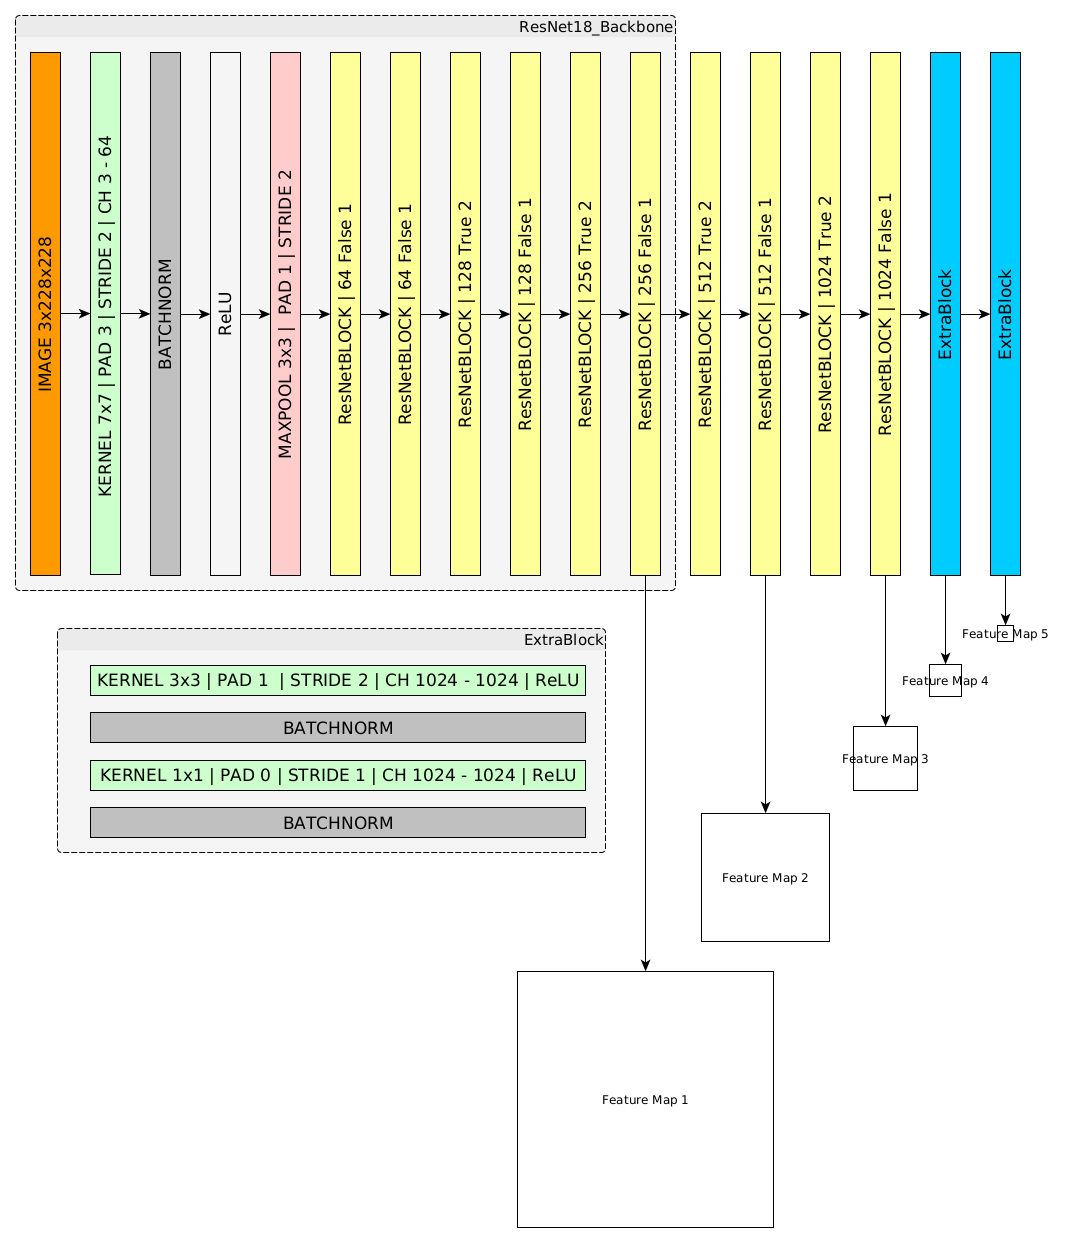

In [5]:
# Твой код здесь
!pip3 install torch torchsummary
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchsummary import summary

#!pip install torchmetrics
#!pip uninstall -y numpy
#!conda remove -y --force numpy
#!rm -rf /home/mlcore/conda/lib/python3.10/site-packages/numpy*
#!pip install --no-cache-dir "numpy==2.2.6"
#!pip install torchvision
import numpy as np
import os
from argparse import Namespace
from tqdm import tqdm
from torchmetrics.detection.mean_ap import MeanAveragePrecision


import json
import albumentations as A
from albumentations.pytorch import ToTensorV2
import voc_dataset

# Импорт наших модулей из прикрепленных файлов
from voc_dataloader import get_train_dataloader, get_test_dataloader
from prior_boxes import prior_boxes, match, encode, decode, detect_objects
from multibox_loss import MultiBoxLoss

def init_cnn(module):
    if type(module) in [nn.Linear, nn.Conv2d]:
        nn.init.xavier_uniform_(module.weight)

# Базовый остаточный блок ResNet18 (BasicBlock)
class BasicBlock(nn.Module):
    def __init__(self, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.LazyConv2d(out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.LazyConv2d(out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        
        self.shortcut = nn.Sequential()
        if stride != 1:
            self.shortcut = nn.Sequential(
                nn.LazyConv2d(out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        # Если размерность каналов не совпадает при stride=1 (на случай адаптации), применяем проекцию
        if out.shape != x.shape and len(self.shortcut) == 0:
            self.shortcut = nn.Sequential(
                nn.Conv2d(x.shape[1], out.shape[1], kernel_size=1, bias=False).to(x.device),
                nn.BatchNorm2d(out.shape[1]).to(x.device)
            )
        out += self.shortcut(x)
        return F.relu(out)

class SSD_ResNet18(nn.Module):
    def __init__(self, num_priors_per_map, num_classes=3):
        super().__init__()
        self.num_classes = num_classes
        self.num_priors_per_map = num_priors_per_map
        
        # --- 1. БЭКБОН (ResNet18) ---
        self.stem = nn.Sequential(
            nn.LazyConv2d(64, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )
        
        # Слой 1: 64 канала (разрешение сохраняется: 90x160)
        self.layer1 = nn.Sequential(
            BasicBlock(64, stride=1),
            BasicBlock(64, stride=1)
        )
        
        # Слой 2: 128 каналов (уменьшение в 2 раза: 45x80)
        self.layer2 = nn.Sequential(
            BasicBlock(128, stride=2),
            BasicBlock(128, stride=1)
        )
        
        # Слой 3: 256 каналов (уменьшение в 2 раза: 23x40) -> 1-я карта признаков!
        self.layer3 = nn.Sequential(
            BasicBlock(256, stride=2),
            BasicBlock(256, stride=1)
        )
        
        # Слой 4: 512 каналов -> 2-я карта признаков!
        # В классическом SSD для ResNet stride в layer4 часто меняют с 2 на 1, 
        # чтобы карта признаков не стала слишком мелкой для детекции (остается 23x40, либо stride=2 -> 12x20)
        self.layer4 = nn.Sequential(
            BasicBlock(512, stride=2),
            BasicBlock(512, stride=1)
        )
        
        # L2 Нормализация для первой карты признаков (256 каналов от layer3)
        self.rescale_channels = nn.Parameter(torch.Tensor(256))
        nn.init.constant_(self.rescale_channels, 20)
        
        # --- 2. ДОПОЛНИТЕЛЬНЫЕ СЛОИ (Auxiliary) ---
        # Карта 3: conv8_2 (уменьшение в 2 раза -> 6x10)
        self.conv8_1 = nn.Sequential(nn.LazyConv2d(256, 1), nn.ReLU())
        self.conv8_2 = nn.Sequential(nn.LazyConv2d(512, 3, stride=2, padding=1), nn.ReLU())
        
        # Карта 4: conv9_2 (уменьшение в 2 раза -> 3x5)
        self.conv9_1 = nn.Sequential(nn.LazyConv2d(128, 1), nn.ReLU())
        self.conv9_2 = nn.Sequential(nn.LazyConv2d(256, 3, stride=2, padding=1), nn.ReLU())
        
        # Карта 5: conv10_2 (без padding -> 1x3)
        self.conv10_1 = nn.Sequential(nn.LazyConv2d(128, 1), nn.ReLU())
        self.conv10_2 = nn.Sequential(nn.LazyConv2d(256, 3, stride=1), nn.ReLU())
        
        # Карта 6: conv11_2 (kernel 1x3 или padding для финального сжатия -> 1x1)
        self.conv11_1 = nn.Sequential(nn.LazyConv2d(128, 1), nn.ReLU())
        self.conv11_2 = nn.Sequential(nn.LazyConv2d(256, kernel_size=(1, 3), stride=1), nn.ReLU())
        
        # --- 3. ПРЕДСКАЗАТЕЛЬНЫЕ СЛОИ (Prediction Convolutions) ---
        self.loc_layers = nn.ModuleList()
        self.conf_layers = nn.ModuleList()
        
        for num_priors in self.num_priors_per_map:
            self.loc_layers.append(nn.LazyConv2d(num_priors * 4, kernel_size=3, padding=1))
            self.conf_layers.append(nn.LazyConv2d(num_priors * self.num_classes, kernel_size=3, padding=1))
            
        self.apply(init_cnn)

    def forward(self, X):
        feature_maps = []
        loc_preds = []
        conf_preds = []
        
        # Проход по бэкбону ResNet18
        X = self.stem(X)
        X = self.layer1(X)
        X = self.layer2(X)
        X = self.layer3(X)
        
        # 1-я карта признаков: выход layer3 (256 каналов) с L2 нормированием
        norm = X.pow(2).sum(dim=1, keepdim=True).sqrt() + 1e-10
        fm1 = (X / norm) * self.rescale_channels.unsqueeze(0).unsqueeze(2).unsqueeze(3)
        feature_maps.append(fm1)
        
        X = self.layer4(X)
        # 2-я карта признаков: выход layer4 (512 каналов)
        feature_maps.append(X)
        
        # Проход по Auxiliary слоям
        X = self.conv8_1(X)
        X = self.conv8_2(X)
        feature_maps.append(X) # 3-я карта
        
        X = self.conv9_1(X)
        X = self.conv9_2(X)
        feature_maps.append(X) # 4-я карта
        
        X = self.conv10_1(X)
        X = self.conv10_2(X)
        feature_maps.append(X) # 5-я карта
        
        X = self.conv11_1(X)
        X = self.conv11_2(X)
        feature_maps.append(X) # 6-я карта
        
        # Сбор предсказаний со всех 6 карт признаков
        for i, fm in enumerate(feature_maps):
            loc = self.loc_layers[i](fm).permute(0, 2, 3, 1).contiguous()
            conf = self.conf_layers[i](fm).permute(0, 2, 3, 1).contiguous()
            
            loc_preds.append(loc.view(loc.size(0), -1))
            conf_preds.append(conf.view(conf.size(0), -1))
            
        loc_preds = torch.cat(loc_preds, dim=1)
        conf_preds = torch.cat(conf_preds, dim=1)
        
        loc_preds = loc_preds.view(loc_preds.size(0), -1, 4)
        conf_preds = conf_preds.view(conf_preds.size(0), -1, self.num_classes)
        
        return loc_preds, conf_preds

# --- ПРОВЕРКА РАЗМЕРНОСТЕЙ ---
priors_config = [4, 6, 6, 6, 4, 4] 
device = "cuda" if torch.cuda.is_available() else "cpu"

model = SSD_ResNet18(num_priors_per_map=priors_config, num_classes=3).to(device)
random_input = torch.rand(1, 3, 720, 1280).to(device)

loc_out, conf_out = model(random_input)

print("Формат вывода локализации: ", loc_out.shape)
print("Формат вывода классификации:", conf_out.shape)

summary(model, input_size=(3, 720, 1280), device=device)

Looking in indexes: https://artifactory.tcsbank.ru/artifactory/api/pypi/python-all/simple

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Формат вывода локализации:  torch.Size([1, 21944, 4])
Формат вывода классификации: torch.Size([1, 21944, 3])
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 360, 640]           9,408
       BatchNorm2d-2         [-1, 64, 360, 640]             128
              ReLU-3         [-1, 64, 360, 640]               0
         MaxPool2d-4         [-1, 64, 180, 320]               0
            Conv2d-5         [-1, 64, 180, 320]          36,864
       BatchNorm2d-6         [-1, 64, 180, 320]             128
            Conv2d-7         [-1, 64, 180, 320]          36,864
       BatchNorm2d-8         [-1, 64, 180, 320]             128
        BasicBlock-9         [-1, 64, 180

In [6]:
# Настройки обучения (адаптированы под ResNet18)
args = Namespace(
    dataset_root_dir='dataset_gs198-05_1280x720',
    #epochs=30,
    epochs=5,
    batch_size=6,
    learning_rate=1e-3,
    momentum=0.9,
    weight_decay=0.0005,
    multistep=[20, 25],
    num_workers=4,
    seed=42,
    output='output'
)

# Конфигурация SSD для базовой SSD_ResNet18
custom_config = {
    'num_classes': 3, # background, car, license_plate
    # Актуальные размеры карт признаков для входа 720x1280:
    'feature_maps': [(45, 80), (23, 40), (12, 20), (6, 10), (4, 8), (4, 6)],
    'min_sizes': [0.10, 0.20, 0.37, 0.54, 0.71, 1.00],
    'max_sizes': [0.20, 0.37, 0.54, 0.71, 1.00, 1.05],
    'aspect_ratios': [[2], [2, 3], [2, 3], [2, 3], [2], [2]],
    'num_priors': [4, 6, 6, 6, 4, 4],
    'variance': [0.1, 0.2],
    'clip': True,
    'overlap_threshold': 0.5,
    'neg_pos_ratio': 3
}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Используемое устройство:", device)

# Инициализация детектора SSD_ResNet18
model = SSD_ResNet18(
    num_priors_per_map=custom_config['num_priors'], 
    num_classes=custom_config['num_classes']
)
model.to(device)

# Обязательный прогрев LazyConv2d перед передачей параметров в оптимизатор!
#with torch.no_grad():
#    dummy_input = torch.zeros(1, 3, 360, 640, device=device)
#    model(dummy_input)

Используемое устройство: cuda


SSD_ResNet18(
  (stem): Sequential(
    (0): LazyConv2d(0, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  )
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): LazyConv2d(0, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): LazyConv2d(0, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (shortcut): Sequential()
    )
    (1): BasicBlock(
      (conv1): LazyConv2d(0, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias

In [7]:
# Пути для сохранения (теперь привязаны к args.output внутри функции)
def build_transforms(target_size=(720, 1280)):
    h, w = target_size
    bbox_params = A.BboxParams(
        format="albumentations",
        min_area=100,
        min_visibility=0.5,
        label_fields=["labels"],
    )

    train_transform = A.Compose(
        [
            A.HorizontalFlip(p=0.5),
            A.RandomResizedCrop(size=(h, w), p=0.5, scale=(0.7, 1.0)),
            A.Resize(height=h, width=w),
            A.RandomBrightnessContrast(p=0.5),
            A.ChannelShuffle(p=0.1),
            A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
            ToTensorV2(),
        ],
        bbox_params=bbox_params,
        p=1.0,
    )

    test_transform = A.Compose(
        [
            A.Resize(height=h, width=w),
            A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
            ToTensorV2(),
        ],
        bbox_params=bbox_params,
        p=1.0,
    )
    return train_transform, test_transform


def train_and_evaluate(model, args, custom_config, target_size=(720, 1280), resume_path=None):
    torch.manual_seed(args.seed)
    np.random.seed(args.seed)

    os.makedirs(args.output, exist_ok=True)
    # Папка для промежуточных чекпоинтов каждой эпохи
    checkpoints_dir = os.path.join(args.output, "checkpoints")
    os.makedirs(checkpoints_dir, exist_ok=True)

    best_weights_path = os.path.join(args.output, "resnet18_ssd_best_weights.pth")
    best_full_model_path = os.path.join(args.output, "resnet18_ssd_best_full_model.pth")
    history_path = os.path.join(args.output, "training_history.json")

    # 1. Создаём трансформации
    train_transform, test_transform = build_transforms(target_size)
    voc_dataset.light_transform = train_transform

    # 2. Загрузчики данных
    train_anno = os.path.join(args.dataset_root_dir, "ImageSets/Main/trainval.txt")
    test_anno = os.path.join(args.dataset_root_dir, "ImageSets/Main/test.txt")

    train_loader = get_train_dataloader(args.dataset_root_dir, train_anno, args.batch_size, num_workers=0)
    test_loader = get_test_dataloader(args.dataset_root_dir, test_anno, args.batch_size, num_workers=0)

    # 3. Генерация априорных боксов
    prior_box_tensor = prior_boxes(custom_config).to(device)

    criterion = MultiBoxLoss(
        overlap_threshold=custom_config["overlap_threshold"],
        neg_pos_ratio=custom_config["neg_pos_ratio"],
        variance=custom_config["variance"],
    ).to(device)

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=args.learning_rate,
        momentum=args.momentum,
        weight_decay=args.weight_decay,
    )
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer=optimizer, milestones=args.multistep)

    start_epoch = 0
    best_map = 0.0
    history = []

    # (Опционально) Загрузка с прерванного места, если передан resume_path
    if resume_path and os.path.exists(resume_path):
        checkpoint = torch.load(resume_path, map_location=device)
        model.load_state_dict(checkpoint["model_state_dict"])
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
        scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
        start_epoch = checkpoint["epoch"] + 1
        best_map = checkpoint.get("best_map", 0.0)
        history = checkpoint.get("history", [])
        print(f"--> Resumed training from epoch {start_epoch}, best mAP: {best_map:.4f}")

    # Сохраняем текстовое описание архитектуры и конфиг перед стартом обучения
    with open(os.path.join(args.output, "model_architecture.txt"), "w", encoding="utf-8") as f:
        f.write(str(model))
    with open(os.path.join(args.output, "config.json"), "w", encoding="utf-8") as f:
        json.dump(custom_config, f, indent=4, default=str)

    for epoch in range(start_epoch, args.epochs):
        # --- Обучение ---
        voc_dataset.light_transform = train_transform
        model.train()
        train_loss = 0.0

        for images, boxes, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{args.epochs} [Train]"):
            if len(boxes) == 0 or len(labels) == 0:
                continue

            images = images.to(device)
            boxes = [b.to(device) for b in boxes]
            labels = [l.to(device) for l in labels]

            targets = (labels, boxes)

            optimizer.zero_grad()
            pred_loc, pred_conf = model(images)

            loc_loss, cls_loss = criterion((pred_loc, pred_conf, prior_box_tensor), targets)
            loss = loc_loss + cls_loss
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

        scheduler.step()
        avg_train_loss = train_loss / len(train_loader)

        # --- Валидация и расчет mAP ---
        voc_dataset.light_transform = test_transform
        model.eval()
        metric = MeanAveragePrecision(class_metrics=True)
        metric.warn_on_many_detections = False

        with torch.no_grad():
            for images, boxes, labels in tqdm(test_loader, desc=f"Epoch {epoch+1} [Eval mAP]"):
                if len(boxes) == 0 or len(labels) == 0:
                    continue

                images = images.to(device)
                pred_loc, pred_conf = model(images)

                pred_conf_softmax = F.softmax(pred_conf, dim=2)

                pred_boxes, pred_labels, pred_scores = detect_objects(
                    pred_loc,
                    pred_conf_softmax,
                    prior_box_tensor,
                    num_classes=custom_config["num_classes"],
                    overlap_threshold=0.45,
                    conf_threshold=0.01,
                )

                preds_metrics = []
                targets_metrics = []

                for b in range(images.size(0)):
                    preds_metrics.append({
                        "boxes": pred_boxes[b].cpu(),
                        "scores": pred_scores[b].cpu(),
                        "labels": pred_labels[b].cpu(),
                    })
                    targets_metrics.append({
                        "boxes": boxes[b],
                        "labels": labels[b],
                    })

                metric.update(preds_metrics, targets_metrics)

        metrics_result = metric.compute()
        current_map = metrics_result["map"].item()
        current_map_50 = metrics_result["map_50"].item()
        current_lr = optimizer.param_groups[0]["lr"]

        print(f"Epoch {epoch+1} | Train Loss: {avg_train_loss:.4f} | Test mAP: {current_map:.4f} | mAP@50: {current_map_50:.4f}")

        # 1. Сохраняем историю метрик в JSON после каждой эпохи
        epoch_stats = {
            "epoch": epoch + 1,
            "train_loss": avg_train_loss,
            "map": current_map,
            "map_50": current_map_50,
            "lr": current_lr,
        }
        history.append(epoch_stats)
        with open(history_path, "w", encoding="utf-8") as f:
            json.dump(history, f, indent=4)

        # 2. Сохраняем полный промежуточный чекпоинт (веса + оптимизатор + шедулер + конфиг)
        checkpoint_data = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "best_map": max(best_map, current_map),
            "custom_config": custom_config,
            "target_size": target_size,
            "history": history,
        }
        # Сохраняем последнюю эпоху (перезаписывается для экономии места)
        torch.save(checkpoint_data, os.path.join(args.output, "last_checkpoint.pth"))
        # Сохраняем именной чекпоинт конкретной эпохи (если нужно откатиться к любой эпохе)
        torch.save(checkpoint_data, os.path.join(checkpoints_dir, f"checkpoint_epoch_{epoch+1:03d}.pth"))

        # 3. Если модель лучшая — сохраняем и чистые веса, и модель целиком (с архитектурой)
        if current_map > best_map:
            best_map = current_map
            # Только веса (рекомендуемый стандарт PyTorch)
            torch.save(model.state_dict(), best_weights_path)
            # Модель целиком вместе с классом архитектуры (через pickle)
            torch.save(model, best_full_model_path)
            print(f"--> Saved new best model (weights & full architecture) with mAP: {best_map:.4f}")

    return model


In [8]:
def optimize_postprocessing(model, test_loader, prior_box_tensor, num_classes):
    model.eval()
    
    # Диапазоны поиска гиперпараметров
    conf_thresholds = [0.01, 0.05, 0.1, 0.2, 0.3]
    overlap_thresholds = [0.2, 0.3, 0.45, 0.5, 0.6]
    
    best_score_th = 0.0
    best_overlap_th = 0.0
    max_map_value = -1.0
    
    print("\n--- Запуск подбора оптимальных порогов постобработки ---")
    
    for conf_th in conf_thresholds:
        for overlap_th in overlap_thresholds:
            metric = MeanAveragePrecision(class_metrics=False)
            
            with torch.no_grad():
                for images, boxes, labels in test_loader:
                    if len(boxes) == 0 or len(labels) == 0:
                        continue
                    images = images.to(device)
                    pred_loc, pred_conf = model(images)
                    pred_conf_softmax = F.softmax(pred_conf, dim=2)
                    
                    # Декодирование боксов с текущими проверяемыми порогами
                    pred_boxes, pred_labels, pred_scores = detect_objects(
                        pred_loc, pred_conf_softmax, prior_box_tensor,
                        num_classes=num_classes,
                        overlap_threshold=overlap_th,
                        conf_threshold=conf_th
                    )
                    
                    preds_metrics = []
                    targets_metrics = []
                    for b in range(images.size(0)):
                        preds_metrics.append({
                            "boxes": pred_boxes[b].cpu(),
                            "scores": pred_scores[b].cpu(),
                            "labels": pred_labels[b].cpu()
                        })
                        targets_metrics.append({
                            "boxes": boxes[b],
                            "labels": labels[b]
                        })
                        
                    metric.update(preds_metrics, targets_metrics)
            
            current_map = metric.compute()['map'].item()
            print(f"Пороги -> conf_threshold: {conf_th}, overlap_threshold (NMS): {overlap_th} | Полученный mAP: {current_map:.4f}")
            
            if current_map > max_map_value:
                max_map_value = current_map
                best_score_th = conf_th
                best_overlap_th = overlap_th
                
    print("\n--- Результаты оптимизации ---")
    print(f"Оптимальный score_threshold: {best_score_th}")
    print(f"Оптимальный overlap_threshold: {best_overlap_th}")
    print(f"Максимальный достигнутый mAP: {max_map_value:.4f}")
    
    return best_score_th, best_overlap_th

In [9]:
print("Инициализация Lazy-слоев реальными данными...")

# 1. Прописываем путь к аннотациям (как в функции обучения)
train_anno = os.path.join(args.dataset_root_dir, "ImageSets/Main/trainval.txt")

# 2. Создаем временный загрузчик данных с размером батча 1
init_loader = get_train_dataloader(
    dataset_root_dir=args.dataset_root_dir,
    annotation_file=train_anno,
    batch_size=1,
    num_workers=0 # ставим 0 для быстрой локальной загрузки в один поток
)

# 3. Достаем один реальный батч
images, boxes, labels = next(iter(init_loader))

# 4. Переносим картинку на нужный девайс и пропускаем через модель
with torch.no_grad():
    real_input = images.to(device)
    _ = model(real_input)

print("Модель успешно скомпилирована на реальных данных!")

Инициализация Lazy-слоев реальными данными...
Модель успешно скомпилирована на реальных данных!


In [10]:
# 4. ЗАПУСК ОБУЧЕНИЯ
trained_model = train_and_evaluate(
    model=model,
    args=args,          
    custom_config=custom_config
)

Epoch 1 [Eval mAP]: 100%|██████████| 11/11 [00:01<00:00,  6.96it/s]


Epoch 1 | Train Loss: 5.3948 | Test mAP: 0.3091 | mAP@50: 0.6941
--> Saved new best model (weights & full architecture) with mAP: 0.3091


Epoch 2 [Eval mAP]: 100%|██████████| 11/11 [00:01<00:00,  6.88it/s]


Epoch 2 | Train Loss: 2.7550 | Test mAP: 0.3893 | mAP@50: 0.7852
--> Saved new best model (weights & full architecture) with mAP: 0.3893


Epoch 3 [Eval mAP]: 100%|██████████| 11/11 [00:01<00:00,  6.80it/s]


Epoch 3 | Train Loss: 2.3176 | Test mAP: 0.4442 | mAP@50: 0.8523
--> Saved new best model (weights & full architecture) with mAP: 0.4442


Epoch 4 [Eval mAP]: 100%|██████████| 11/11 [00:01<00:00,  7.39it/s]


Epoch 4 | Train Loss: 2.0962 | Test mAP: 0.4224 | mAP@50: 0.8423


Epoch 5 [Eval mAP]: 100%|██████████| 11/11 [00:01<00:00,  6.75it/s]


Epoch 5 | Train Loss: 1.9181 | Test mAP: 0.4618 | mAP@50: 0.8503
--> Saved new best model (weights & full architecture) with mAP: 0.4618


In [14]:
# Пример запуска после обучения для SSD_ResNet18:
# 1. Инициализируем модель и прогреваем Lazy-слои перед загрузкой весов
model = SSD_ResNet18(
    num_priors_per_map=custom_config['num_priors'], 
    num_classes=custom_config['num_classes']
).to(device)

with torch.no_grad():
    dummy_input = torch.zeros(1, 3, 720, 1280, device=device)
    model(dummy_input)

# 2. Загружаем сохраненные веса и переводим в режим оценки (важно для BatchNorm!)
model.load_state_dict(torch.load(os.path.join(args.output, "resnet18_ssd_best_weights.pth"), map_location=device))
model.eval()

# 3. Загружаем тестовый датасет и генерируем якоря под custom_config от ResNet18
test_anno = os.path.join(args.dataset_root_dir, "ImageSets/Main/test.txt")
test_loader = get_test_dataloader(args.dataset_root_dir, test_anno, args.batch_size, args.num_workers)
prior_box_tensor = prior_boxes(custom_config).to(device)

# 4. Подбор оптимальных порогов постобработки
best_score_th, best_overlap_th = optimize_postprocessing(
    model, 
    test_loader, 
    prior_box_tensor, 
    custom_config['num_classes']
)



--- Запуск подбора оптимальных порогов постобработки ---
Пороги -> conf_threshold: 0.01, overlap_threshold (NMS): 0.2 | Полученный mAP: 0.4625


/home/mlcore/conda/lib/python3.10/site-packages/torchmetrics/utilities/prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)


Пороги -> conf_threshold: 0.01, overlap_threshold (NMS): 0.3 | Полученный mAP: 0.4625
Пороги -> conf_threshold: 0.01, overlap_threshold (NMS): 0.45 | Полученный mAP: 0.4618
Пороги -> conf_threshold: 0.01, overlap_threshold (NMS): 0.5 | Полученный mAP: 0.4611
Пороги -> conf_threshold: 0.01, overlap_threshold (NMS): 0.6 | Полученный mAP: 0.4585
Пороги -> conf_threshold: 0.05, overlap_threshold (NMS): 0.2 | Полученный mAP: 0.4601
Пороги -> conf_threshold: 0.05, overlap_threshold (NMS): 0.3 | Полученный mAP: 0.4596
Пороги -> conf_threshold: 0.05, overlap_threshold (NMS): 0.45 | Полученный mAP: 0.4583
Пороги -> conf_threshold: 0.05, overlap_threshold (NMS): 0.5 | Полученный mAP: 0.4575
Пороги -> conf_threshold: 0.05, overlap_threshold (NMS): 0.6 | Полученный mAP: 0.4532
Пороги -> conf_threshold: 0.1, overlap_threshold (NMS): 0.2 | Полученный mAP: 0.4533
Пороги -> conf_threshold: 0.1, overlap_threshold (NMS): 0.3 | Полученный mAP: 0.4527
Пороги -> conf_threshold: 0.1, overlap_threshold (NMS)

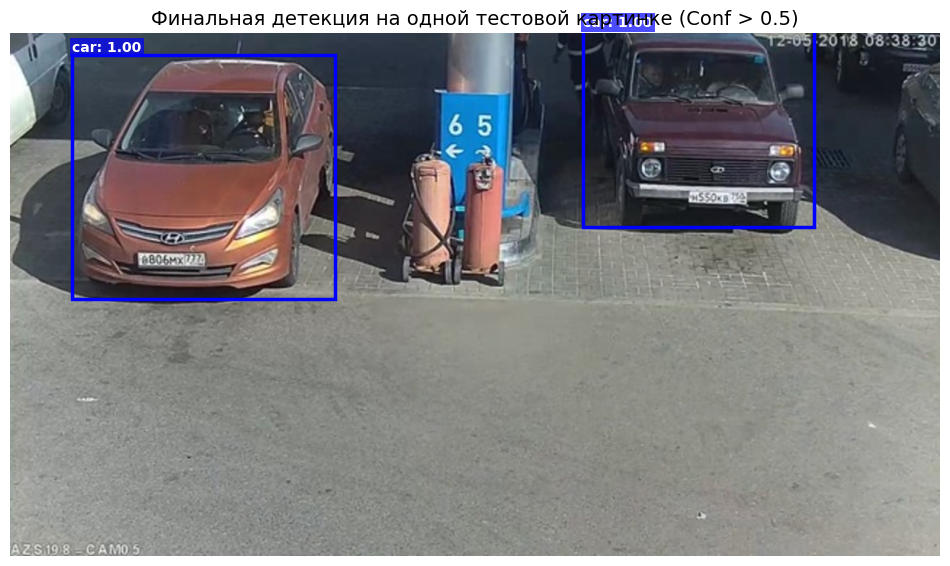

In [15]:
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import numpy as np

def draw_single_image_predictions(model, test_loader, prior_box_tensor):
    model.eval()
    
    # 1. Извлекаем ровно ОДИН батч и берём из него только ПЕРВУЮ картинку
    images, target_boxes, target_labels = next(iter(test_loader))
    single_img_tensor = images[0].unsqueeze(0).to(device) # Размерность [1, 3, H, W]
    
    # 2. Делаем предсказание только для этого одного изображения
    with torch.no_grad():
        pred_loc, pred_conf = model(single_img_tensor)
        pred_conf_softmax = F.softmax(pred_conf, dim=2)
        
        # Фильтруем шум: поднимаем порог conf_threshold до 0.5!
        pred_boxes, pred_labels, pred_scores = detect_objects(
            pred_loc, pred_conf_softmax, prior_box_tensor,
            num_classes=3,
            overlap_threshold=best_overlap_th,   # Порог для подавления дубликатов (NMS)
            conf_threshold=0.50       # Оставляем только уверенные предсказания (>50%)
        )
    
    # 3. Готовим картинку к отрисовке (переводим из [3, H, W] в [H, W, 3])
    img_np = images[0].permute(1, 2, 0).cpu().numpy()
    
    # Повышаем яркость и контраст
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img_np = (img_np * std) + mean
    
    img_np = np.clip(img_np, 0, 1)
    height, width, _ = img_np.shape
    
    # 4. Отрисовка
    fig, ax = plt.subplots(1, 1, figsize=(12, 7))
    ax.imshow(img_np)
    
    # Словари для красивого отображения рамок
    label_map = {1: 'car', 2: 'license_plate'}
    colors = {1: 'blue', 2: 'red'}
    
    # Извлекаем предсказания (убираем батч-размерность)
    boxes = pred_boxes[0].cpu().numpy()
    labels = pred_labels[0].cpu().numpy()
    scores = pred_scores[0].cpu().numpy()
    
    for box, label, score in zip(boxes, labels, scores):
        if label == 0: # Пропускаем background
            continue
            
        # Координаты рамки
        xmin, ymin, xmax, ymax = box
        
        # Перевод из относительных координат (0..1) в пиксели изображения
        x = xmin * width
        y = ymin * height
        w = (xmax - xmin) * width
        h = (ymax - ymin) * height
        
        # Рисуем bounding box
        rect = patches.Rectangle((x, y), w, h, linewidth=2.5, edgecolor=colors[label], facecolor='none')
        ax.add_patch(rect)
        
        # Добавляем подпись класса и точности
        text = f"{label_map[label]}: {score:.2f}"
        ax.text(x, y - 5, text, color='white', fontsize=10, fontweight='bold',
                bbox=dict(facecolor=colors[label], alpha=0.7, pad=2, edgecolor='none'))
        
    plt.axis('off')
    plt.title("Финальная детекция на одной тестовой картинке (Conf > 0.5)", fontsize=14)
    plt.show()

# Запуск функции
draw_single_image_predictions(model, test_loader, prior_box_tensor)

Как видно на рисунке выше, модель точно и с уверенностью распознала оба основных автомобиля на переднем плане, но пропустила машины, частично попавшие в кадр по краям.

--- Результаты оптимизации VGG16 30 эпох---
Оптимальный score_threshold: 0.01
Оптимальный overlap_threshold: 0.45
Максимальный достигнутый mAP: 0.4198

--- Результаты оптимизации ---
Оптимальный score_threshold: 0.01
Оптимальный overlap_threshold: 0.2
Максимальный достигнутый mAP: 0.4625

Вывод:
Модель на базе ResNet18 превосходит VGG16 по метрике mAP на +0.0674 (+16.05% относительного прироста), достигнув 0.4625 всего за 5 эпох против 0.4198 за 30 эпох у VGG16.

Модель на базе VGG16 работает примерно в 2,3 раза быстрее в пересчёте на одну эпоху обучения и валидации,